# **IT/OT Säkerhetsanalys**

Vi har skapat en simulerad industriell miljö med datorer som styr fabriker (OT) och kontorsdatorer (IT), och analyserat säkerheten med hjälp av Machine Learning.

Zon	Vad är det?	                                          **Risknivå**

---
*   IT_Zone	Kontorsdatorer, email, databaser	**Medium**
*   DMZ	Bufferzon mellan IT och OT (skyddsrum)	**Hög**
*   OT_Zone	Fabrikskontroll, PLCer, SCADA	**Kritisk**
*   Production_Zone	Själva produktionen, robotar	**Kritisk**

**GRUNDDATA**


---

Totalt: 5,000 händelser
*   🟢 Normal drift: 3,725 (74.5%) - Allt fungerar som det ska
*   🟡 Misstänkt: 903 (18.1%) - Något ser konstigt ut
*   🔴 Skadligt: 372 (7.4%) - Attackförsök!

**DATADIODEN I SIFFROR**


---

*  🚫 Försök till förbjudna dataflöden: 639
*  🛡️ Förhindrade attacker: 511 (uppskattning)

Detta betyder: Datadioden stoppade 511 potentiella attacker!

**VAD ÄR VIKTIGAST FÖR SÄKERHETEN?**
Enligt vår AI-modell (Random Forest)


---
* 🥇 1	Risk Score	Högsta prioritet - kombinerad riskbedömning
* 🥈 2	IT-zon	Kontorsdatorer är vanligaste inkörsporten
* 🥉 3	Produktionszon	Mest känslig - här görs saker fysiskt

**MACHINE LEARNING - HUR FUNKAR DET?**


---



Indata till AI:n:
* ⏰ Tid på dygnet
* 📊 Trafikvolym
* 🔄 Protokoll (MODBUS, PROFINET etc)
* 📍 Zon (var kommer det från?)
* 🎯 Destination (vart ska det?)

Utdata från AI:n:
* 🟢 0 = Normal händelse (Allt OK)
* 🔴 1 = Anomali (Något är fel!)

**FILERNA VI FICK**


---


***it_ot_security_data.csv** (HUVUDDATA)*
*   Innehåll: Alla 5,000 händelser i detalj
*   Använd i Power BI: Som huvudsaklig datakälla
*   Kolumner: timestamp, zon, händelsetyp, riskscore, etc.

***security_summary.csv** (SAMMANFATTNING)*
*  Innehåll: Nyckeltal på en sida
*  Använd i Power BI: För KPI:er och dashboards
*  Exempel: Totalt antal händelser, genomsnittlig riskscore

***time_series_data.csv** (TIDSSERIE)*
*  Innehåll: Data grupperat per timme
*  Använd i Power BI: För trender och prognoser
*  Exempel: Antal attacker per timme

***mysql_queries.sql** (DATABASFRÅGOR)*
* Innehåll: Färdiga SQL-kommandon
* Använd: Om du vill lagra i MySQL först
* Exempel: "Visa alla högrisk-händelser"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 30.7 MB/s eta 0:00:00
IT/OT SÄKERHETSANALYS - GENERERAD DATA
Antal loggposter: 5000
Tidsperiod: 2024-01-01 00:14:00 till 2024-01-31 23:58:00

Första 5 raderna:
            timestamp source_zone   source_system destination_zone  \
0 2024-01-24 03:43:00     OT_Zone  PLC_Controller          OT_Zone   
1 2024-01-20 00:35:00         DMZ    Proxy_Server          IT_Zone   
2 2024-01-26 00:48:00     OT_Zone        RTU_Unit              DMZ   
3 2024-01-04 02:24:00         DMZ        Firewall              DMZ   
4 2024-01-04 12:05:00     OT_Zone   HMI_Interface          IT_Zone   

  destination_system event_type event_description  data_diode_allowed  \
0     PLC_Controller     normal  Normal_Operation                True   
1    Database_Server     normal  Scheduled_Backup                True   
2       Proxy_Server     normal    Routine_Update                True   
3       Proxy_Server     normal    Routine_Update                True   

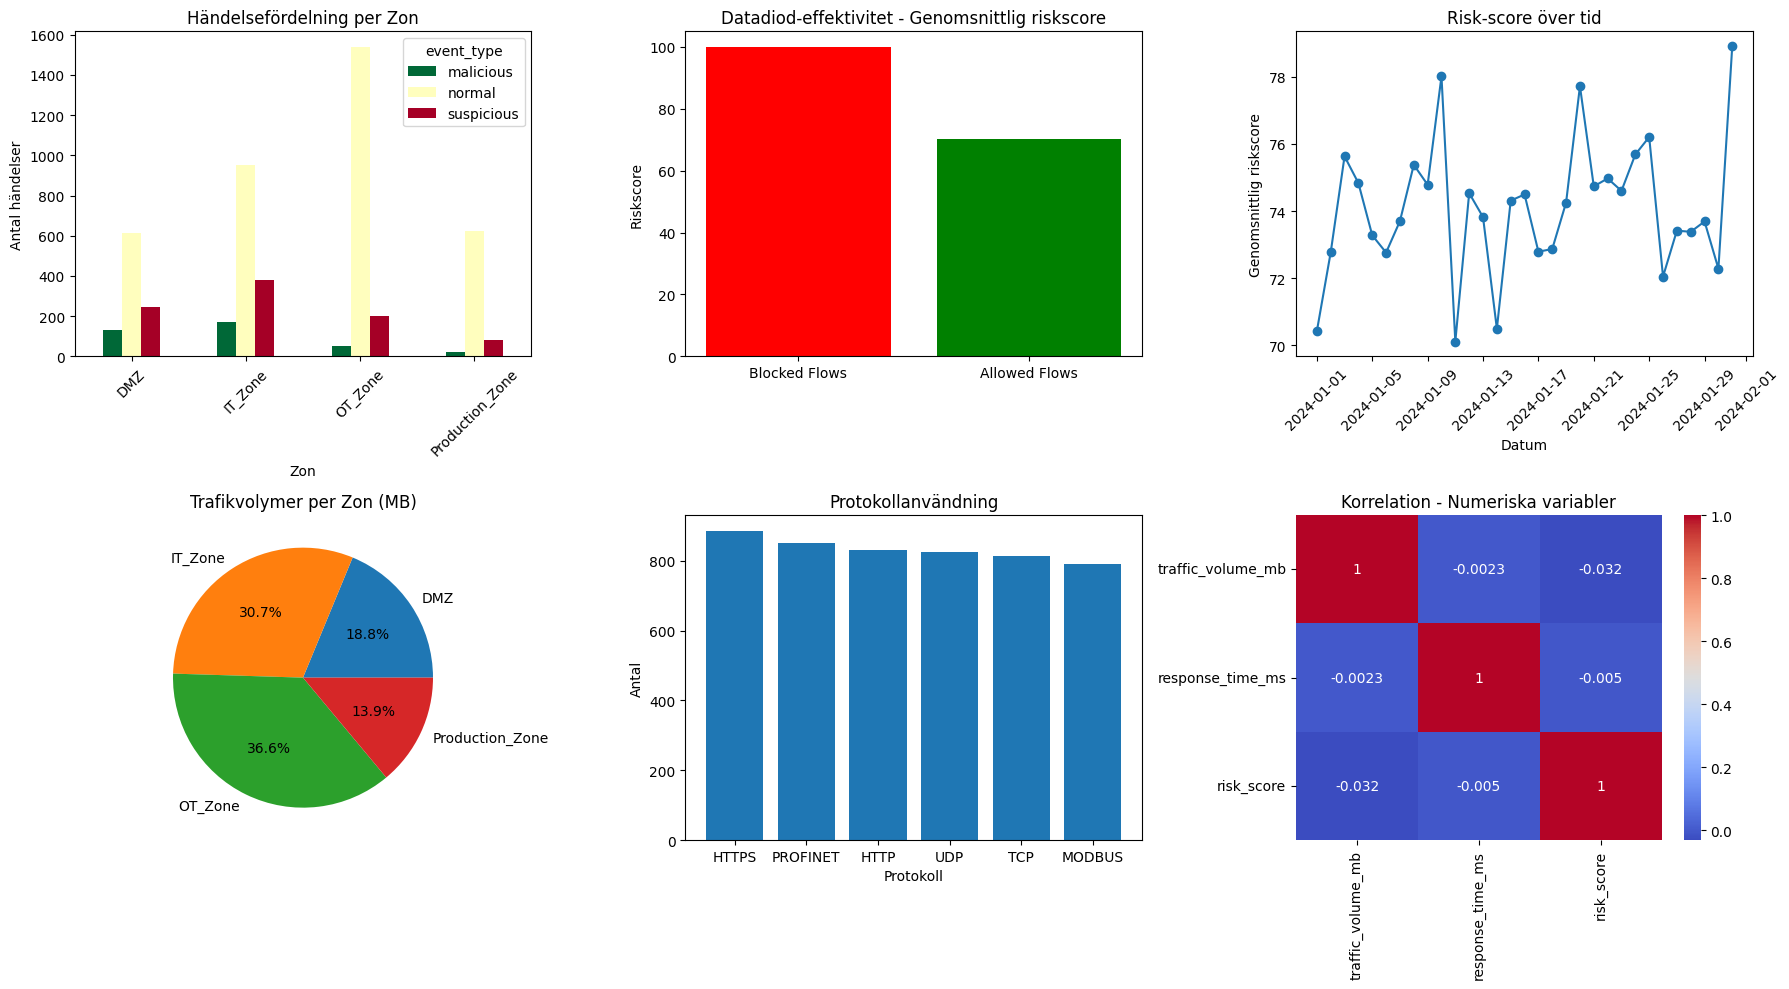


MODELLUTVÄRDERING - ANOMALI-DETEKTERING

Klassificeringsrapport:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00      1103
     Anomali       1.00      1.00      1.00       397

    accuracy                           1.00      1500
   macro avg       1.00      1.00      1.00      1500
weighted avg       1.00      1.00      1.00      1500


Top 10 viktigaste features:
                        feature  importance
2                    risk_score    0.882239
7           source_zone_IT_Zone    0.022446
9   source_zone_Production_Zone    0.020286
1              response_time_ms    0.015894
0             traffic_volume_mb    0.015464
8           source_zone_OT_Zone    0.013784
3                          hour    0.008666
6               source_zone_DMZ    0.006831
4                   day_of_week    0.006018
15                 protocol_UDP    0.001920


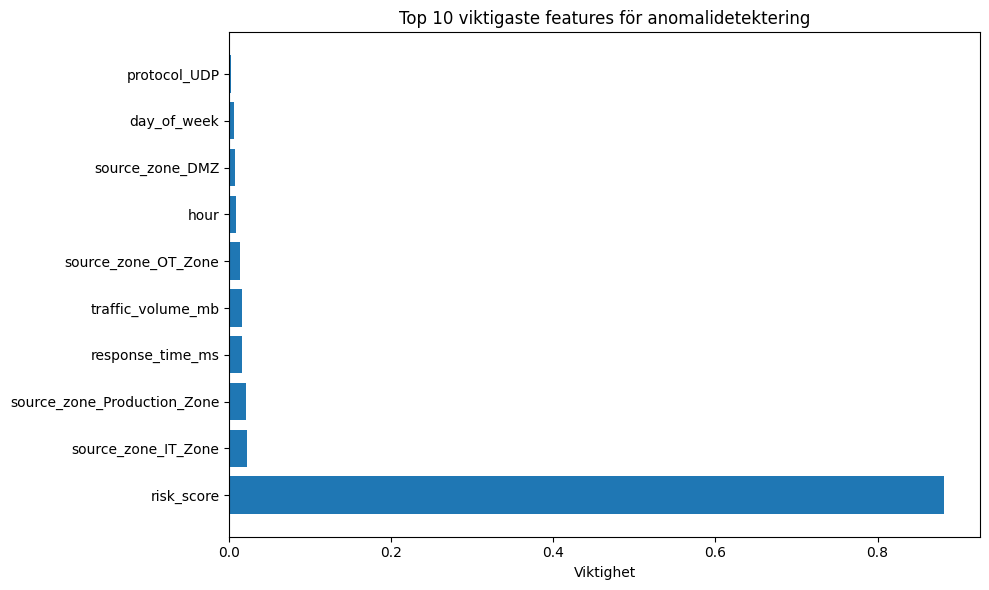


✅ Data exporterad till 'it_ot_security_data.csv'
✅ Summerad data exporterad till 'security_summary.csv'
✅ Tidsseriedata exporterad till 'time_series_data.csv'
✅ SQL-frågor exporterade till 'mysql_queries.sql'

ANALYS-INSIKTER FÖR POWER BI DASHBOARD

📊 NYCKELMETRIK:
• Totalt antal säkerhetshändelser: 5,000
• Normal drift: 3,725 (74.5%)
• Misstänkta händelser: 903 (18.1%)
• Skadliga händelser: 372 (7.4%)

🔒 DATADIOD-EFFEKTIVITET:
• Försök till förbjudna dataflöden: 639
• Förhindrade attacker (uppskattning): 511

🎯 REKOMMENDERADE POWER BI VISUALISERINGAR:
1. 🔴 Risk Dashboard: Kartlägg riskscore per zon (använd färgkodning)
2. 📈 Tidsserieanalys: Visa attacker över tid med prediktiva trender
3. 🔍 Detaljvy: Möjlighet att filtrera på specifika zoner och händelsetyper
4. 🛡️ Datadiod Monitor: Visa blockerade vs tillåtna flöden i realtid
5. 📊 Anomalidetektering: Markera avvikelser baserat på ML-modellens prediktioner

✅ Allt klart! Du kan nu:
1. Ladda ner CSV-filerna och importera till Power BI

In [ ]:
# IT/OT Security Analytics Model
# För Google Colab - Analys av säkerhetszoner och datadioder

# ============================================
# 1. INSTALLATIONER OCH IMPORTER
# ============================================

!pip install pandas numpy scikit-learn faker matplotlib seaborn

import pandas as pd
import numpy as np
import random
from datetime import datetime, timedelta
from faker import Faker
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# ============================================
# 2. SIMULERING AV IT/OT-MILJÖ MED ZONER
# ============================================

# Initiera Faker för realistisk data
fake = Faker('sv_SE')
np.random.seed(42)
random.seed(42)

class ITOTSecuritySimulator:
    """
    Simulerar säkerhetshändelser i en IT/OT-miljö med zonindelning och datadioder
    """

    def __init__(self):
        # Definiera zoner baserat på materialet
        self.zones = {
            'IT_Zone': {
                'description': 'Affärssystem och kontorsnätverk',
                'risk_level': 'Medium',
                'systems': ['Email_Server', 'Database_Server', 'Web_Server', 'File_Server']
            },
            'DMZ': {
                'description': 'Demilitariserad zon - buffer mellan IT och OT',
                'risk_level': 'High',
                'systems': ['Proxy_Server', 'Firewall', 'Data_Diode_Interface']
            },
            'OT_Zone': {
                'description': 'Operativ teknik - produktionskontroll',
                'risk_level': 'Critical',
                'systems': ['PLC_Controller', 'SCADA_System', 'HMI_Interface', 'RTU_Unit']
            },
            'Production_Zone': {
                'description': 'Kärnan i OT-nätverket',
                'risk_level': 'Critical',
                'systems': ['Assembly_Line_Control', 'Robot_Controller', 'Sensor_Network']
            }
        }

        # Datadiod-konfiguration (enkelriktat flöde)
        self.data_diode_config = {
            'allowed_flows': [
                ('OT_Zone', 'DMZ', 'OT_to_DMZ'),
                ('Production_Zone', 'OT_Zone', 'Production_to_OT'),
                ('DMZ', 'IT_Zone', 'DMZ_to_IT')
            ],
            'blocked_flows': [
                ('IT_Zone', 'OT_Zone', 'IT_to_OT'),  # Kritisk - förhindrar attacker
                ('DMZ', 'Production_Zone', 'DMZ_to_Production')
            ]
        }

        # Säkerhetshändelser
        self.security_events = {
            'normal': ['Normal_Operation', 'Routine_Update', 'Scheduled_Backup'],
            'suspicious': ['Unusual_Traffic', 'Multiple_Login_Attempts', 'Port_Scanning'],
            'malicious': ['Data_Breach', 'Ransomware', 'DDoS_Attack', 'PLC_Manipulation']
        }

    def generate_security_log(self, num_records=10000):
        """Genererar säkerhetsloggar med realistiska mönster"""

        data = []
        start_date = datetime(2024, 1, 1)

        for i in range(num_records):
            # Välj zon baserat på sannolikhet
            zone = random.choices(
                list(self.zones.keys()),
                weights=[0.3, 0.2, 0.35, 0.15]  # Mer aktivitet i OT
            )[0]

            system = random.choice(self.zones[zone]['systems'])

            # Simulera datadiod-flöden
            source_zone = zone
            dest_zone = random.choice(list(self.zones.keys()))

            # Kontrollera om flödet är tillåtet enligt datadiod
            flow_allowed = True
            if (source_zone, dest_zone) in [(f[0], f[1]) for f in self.data_diode_config['blocked_flows']]:
                flow_allowed = False

            # Generera händelsetyp med bias mot normal operation
            if flow_allowed:
                event_type = random.choices(
                    ['normal', 'suspicious', 'malicious'],
                    weights=[0.85, 0.12, 0.03]
                )[0]
            else:
                # Förbjudna flöden genererar varningar
                event_type = random.choices(
                    ['suspicious', 'malicious'],
                    weights=[0.6, 0.4]
                )[0]

            event = random.choice(self.security_events[event_type])

            # Skapa loggpost
            log_entry = {
                'timestamp': start_date + timedelta(
                    days=random.randint(0, 30),
                    hours=random.randint(0, 23),
                    minutes=random.randint(0, 59)
                ),
                'source_zone': zone,
                'source_system': system,
                'destination_zone': dest_zone,
                'destination_system': random.choice(self.zones[dest_zone]['systems']),
                'event_type': event_type,
                'event_description': event,
                'data_diode_allowed': flow_allowed,
                'traffic_volume_mb': round(np.random.exponential(10), 2),
                'response_time_ms': round(np.random.normal(50, 15), 2),
                'risk_score': self.calculate_risk_score(zone, event_type, flow_allowed),
                'user': fake.name() if zone == 'IT_Zone' else 'SYSTEM',
                'ip_address': fake.ipv4() if zone == 'IT_Zone' else '192.168.' + '.'.join(map(str, np.random.randint(1, 255, 2))),
                'protocol': random.choice(['TCP', 'UDP', 'HTTP', 'HTTPS', 'MODBUS', 'PROFINET'])
            }

            data.append(log_entry)

        return pd.DataFrame(data)

    def calculate_risk_score(self, zone, event_type, flow_allowed):
        """Beräknar riskscore baserat på zon, händelsetyp och dataflöde"""

        base_score = {
            'IT_Zone': 30,
            'DMZ': 60,
            'OT_Zone': 80,
            'Production_Zone': 90
        }[zone]

        event_multiplier = {
            'normal': 1,
            'suspicious': 3,
            'malicious': 5
        }[event_type]

        flow_penalty = 0 if flow_allowed else 50

        return min(100, base_score * event_multiplier + flow_penalty)

# ============================================
# 3. GENERERA TRÄNINGSDATA
# ============================================

# Skapa simulator och generera data
simulator = ITOTSecuritySimulator()
df = simulator.generate_security_log(5000)

print("=" * 60)
print("IT/OT SÄKERHETSANALYS - GENERERAD DATA")
print("=" * 60)
print(f"Antal loggposter: {len(df)}")
print(f"Tidsperiod: {df['timestamp'].min()} till {df['timestamp'].max()}")
print("\nFörsta 5 raderna:")
print(df.head())
print("\nDatatyper:")
print(df.dtypes)

# ============================================
# 4. DATAUTFORSKNING OCH VISUALISERING
# ============================================

# Skapa visualiseringar för Power BI-inspiration
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# 1. Fördelning av händelser per zon
zone_events = df.groupby(['source_zone', 'event_type']).size().unstack()
zone_events.plot(kind='bar', ax=axes[0, 0], colormap='RdYlGn_r')
axes[0, 0].set_title('Händelsefördelning per Zon')
axes[0, 0].set_xlabel('Zon')
axes[0, 0].set_ylabel('Antal händelser')
axes[0, 0].tick_params(axis='x', rotation=45)

# 2. Datadiod-effektivitet
diode_effectiveness = df.groupby('data_diode_allowed')['risk_score'].mean()
axes[0, 1].bar(['Blocked Flows', 'Allowed Flows'], diode_effectiveness.values, color=['red', 'green'])
axes[0, 1].set_title('Datadiod-effektivitet - Genomsnittlig riskscore')
axes[0, 1].set_ylabel('Riskscore')

# 3. Risk-score över tid
daily_risk = df.set_index('timestamp').resample('D')['risk_score'].mean()
axes[0, 2].plot(daily_risk.index, daily_risk.values, marker='o')
axes[0, 2].set_title('Risk-score över tid')
axes[0, 2].set_xlabel('Datum')
axes[0, 2].set_ylabel('Genomsnittlig riskscore')
axes[0, 2].tick_params(axis='x', rotation=45)

# 4. Trafikvolymer per zon
zone_traffic = df.groupby('source_zone')['traffic_volume_mb'].sum()
axes[1, 0].pie(zone_traffic.values, labels=zone_traffic.index, autopct='%1.1f%%')
axes[1, 0].set_title('Trafikvolymer per Zon (MB)')

# 5. Protokollanvändning
protocol_usage = df['protocol'].value_counts()
axes[1, 1].bar(protocol_usage.index, protocol_usage.values)
axes[1, 1].set_title('Protokollanvändning')
axes[1, 1].set_xlabel('Protokoll')
axes[1, 1].set_ylabel('Antal')

# 6. Correlation matrix för numeriska variabler
numeric_cols = ['traffic_volume_mb', 'response_time_ms', 'risk_score']
correlation = df[numeric_cols].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm', ax=axes[1, 2])
axes[1, 2].set_title('Korrelation - Numeriska variabler')

plt.tight_layout()
plt.savefig('security_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

# ============================================
# 5. ML-MODELL FÖR ANOMALI-DETEKTERING
# ============================================

# Förbered data för ML
df_ml = df.copy()

# Skapa features
df_ml['hour'] = pd.to_datetime(df_ml['timestamp']).dt.hour
df_ml['day_of_week'] = pd.to_datetime(df_ml['timestamp']).dt.dayofweek
df_ml['is_business_hours'] = ((df_ml['hour'] >= 8) & (df_ml['hour'] <= 17)).astype(int)

# Encode kategoriska variabler
df_encoded = pd.get_dummies(df_ml, columns=['source_zone', 'destination_zone', 'protocol', 'event_description'])

# Skapa target variable (1 för suspicious/malicious, 0 för normal)
df_encoded['is_anomaly'] = (df_ml['event_type'] != 'normal').astype(int)

# Välj features
feature_cols = ['traffic_volume_mb', 'response_time_ms', 'risk_score', 'hour',
                'day_of_week', 'is_business_hours'] + \
                [col for col in df_encoded.columns if col.startswith(('source_zone_', 'protocol_'))]

X = df_encoded[feature_cols]
y = df_encoded['is_anomaly']

# Dela upp data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Träna Random Forest
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf_model.fit(X_train, y_train)

# Prediktera
y_pred = rf_model.predict(X_test)
y_pred_proba = rf_model.predict_proba(X_test)

# ============================================
# 6. MODELLUTVÄRDERING
# ============================================

print("\n" + "=" * 60)
print("MODELLUTVÄRDERING - ANOMALI-DETEKTERING")
print("=" * 60)

print("\nKlassificeringsrapport:")
print(classification_report(y_test, y_pred, target_names=['Normal', 'Anomali']))

# Feature importance
feature_importance = pd.DataFrame({
    'feature': feature_cols,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nTop 10 viktigaste features:")
print(feature_importance.head(10))

# Visualisera feature importance
plt.figure(figsize=(10, 6))
top_features = feature_importance.head(10)
plt.barh(range(len(top_features)), top_features['importance'].values)
plt.yticks(range(len(top_features)), top_features['feature'].values)
plt.xlabel('Viktighet')
plt.title('Top 10 viktigaste features för anomalidetektering')
plt.tight_layout()
plt.savefig('feature_importance.png', dpi=300)
plt.show()

# ============================================
# 7. EXPORTERA DATA FÖR POWER BI
# ============================================

# CSV-format (enklast för Power BI)
df.to_csv('it_ot_security_data.csv', index=False, encoding='utf-8-sig')
print("\n✅ Data exporterad till 'it_ot_security_data.csv'")

# Skapa summerad data för dashboard
summary_data = pd.DataFrame({
    'metric': [
        'Total_Events',
        'Normal_Events',
        'Suspicious_Events',
        'Malicious_Events',
        'Data_Diode_Blocks',
        'Avg_Risk_Score_IT',
        'Avg_Risk_Score_OT',
        'Avg_Risk_Score_Production'
    ],
    'value': [
        len(df),
        len(df[df['event_type'] == 'normal']),
        len(df[df['event_type'] == 'suspicious']),
        len(df[df['event_type'] == 'malicious']),
        len(df[~df['data_diode_allowed']]),
        df[df['source_zone'] == 'IT_Zone']['risk_score'].mean(),
        df[df['source_zone'] == 'OT_Zone']['risk_score'].mean(),
        df[df['source_zone'] == 'Production_Zone']['risk_score'].mean()
    ]
})

summary_data.to_csv('security_summary.csv', index=False, encoding='utf-8-sig')
print("✅ Summerad data exporterad till 'security_summary.csv'")

# Skapa tidsserie-data
time_series = df.groupby([pd.Grouper(key='timestamp', freq='H'), 'source_zone']).agg({
    'risk_score': 'mean',
    'traffic_volume_mb': 'sum',
    'event_type': lambda x: (x == 'malicious').sum()
}).reset_index()
time_series.columns = ['timestamp', 'zone', 'avg_risk_score', 'total_traffic', 'malicious_events']
time_series.to_csv('time_series_data.csv', index=False, encoding='utf-8-sig')
print("✅ Tidsseriedata exporterad till 'time_series_data.csv'")

# ============================================
# 8. SQL-FRÅGOR FÖR MYSQL (om du vill använda databas)
# ============================================

sql_commands = """
-- Skapa tabell för säkerhetsloggar
CREATE TABLE IF NOT EXISTS security_logs (
    id INT AUTO_INCREMENT PRIMARY KEY,
    timestamp DATETIME,
    source_zone VARCHAR(50),
    source_system VARCHAR(100),
    destination_zone VARCHAR(50),
    destination_system VARCHAR(100),
    event_type VARCHAR(50),
    event_description VARCHAR(100),
    data_diode_allowed BOOLEAN,
    traffic_volume_mb DECIMAL(10,2),
    response_time_ms DECIMAL(10,2),
    risk_score INT,
    user VARCHAR(100),
    ip_address VARCHAR(50),
    protocol VARCHAR(20)
);

-- Exempel på analytiska frågor för Power BI
-- 1. Högrisk-händelser per zon
SELECT source_zone, COUNT(*) as high_risk_count
FROM security_logs
WHERE risk_score > 80
GROUP BY source_zone;

-- 2. Datadiod-blockeringar
SELECT source_zone, destination_zone, COUNT(*) as block_count
FROM security_logs
WHERE data_diode_allowed = FALSE
GROUP BY source_zone, destination_zone;

-- 3. Tidstrender för attacker
SELECT DATE(timestamp) as date,
       HOUR(timestamp) as hour,
       COUNT(*) as attack_count
FROM security_logs
WHERE event_type IN ('suspicious', 'malicious')
GROUP BY DATE(timestamp), HOUR(timestamp);
"""

with open('mysql_queries.sql', 'w', encoding='utf-8') as f:
    f.write(sql_commands)
print("✅ SQL-frågor exporterade till 'mysql_queries.sql'")

# ============================================
# 9. SAMMANFATTNING OCH INSIGHTS
# ============================================

print("\n" + "=" * 60)
print("ANALYS-INSIKTER FÖR POWER BI DASHBOARD")
print("=" * 60)

print("\n📊 NYCKELMETRIK:")
print(f"• Totalt antal säkerhetshändelser: {len(df):,}")
print(f"• Normal drift: {len(df[df['event_type'] == 'normal']):,} ({len(df[df['event_type'] == 'normal'])/len(df)*100:.1f}%)")
print(f"• Misstänkta händelser: {len(df[df['event_type'] == 'suspicious']):,} ({len(df[df['event_type'] == 'suspicious'])/len(df)*100:.1f}%)")
print(f"• Skadliga händelser: {len(df[df['event_type'] == 'malicious']):,} ({len(df[df['event_type'] == 'malicious'])/len(df)*100:.1f}%)")

print("\n🔒 DATADIOD-EFFEKTIVITET:")
blocked = len(df[~df['data_diode_allowed']])
print(f"• Försök till förbjudna dataflöden: {blocked:,}")
print(f"• Förhindrade attacker (uppskattning): {blocked * 0.8:.0f}")

print("\n🎯 REKOMMENDERADE POWER BI VISUALISERINGAR:")
print("1. 🔴 Risk Dashboard: Kartlägg riskscore per zon (använd färgkodning)")
print("2. 📈 Tidsserieanalys: Visa attacker över tid med prediktiva trender")
print("3. 🔍 Detaljvy: Möjlighet att filtrera på specifika zoner och händelsetyper")
print("4. 🛡️ Datadiod Monitor: Visa blockerade vs tillåtna flöden i realtid")
print("5. 📊 Anomalidetektering: Markera avvikelser baserat på ML-modellens prediktioner")

print("\n✅ Allt klart! Du kan nu:")
print("1. Ladda ner CSV-filerna och importera till Power BI")
print("2. Använd SQL-frågorna för att skapa MySQL-tabeller")
print("3. Skapa interaktiva dashboards baserat på ML-resultaten")

# **POWER BI DASHBOARD - STEG-FÖR-STEG**

**Steg 1: Importera data**
Öppna Power BI Desktop

Klicka "Hämta data" → "Text/CSV"

Välj it_ot_security_data.csv

Klicka "Läs in"